# 02 · The metric and the baselines

**Purpose.** Decide *how* models will be compared, and find out how good the simple alternatives already are. By the end we know:

1. how the city's **current order** performs,
2. how much a **perfect ranking** (the oracle) could gain, i.e. the headroom,
3. how far two **no-ML rules** get, the bar every model in notebook 03 must clear.

**Setting.** Each month the city makes a certain number of routine visits. We keep that number fixed and only change the **order**. A good order puts visits that will find a Priority violation (a *hit*, notebook 01) early in the month.

**Data used.** Routine visits from the train and validation periods (2020–2024). The baselines involve no training, so looking at the train years is safe. The **test period (2025–26) is not touched** (asserted below).

**Risks checked:** R10 headroom · R11 monthly pool size · R14 as-of features · R23 reproducibility.

## 0 · Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

from inspections import config

pd.set_option('display.width', 150)
rng = np.random.default_rng(config.SEED)
EARTH_RADIUS_M = 6_371_000

visits = pd.read_parquet(config.PROCESSED / 'visits.parquet')
licenses = pd.read_parquet(config.PROCESSED / 'licenses.parquet')
complaints = pd.read_parquet(config.PROCESSED / 'complaints.parquet')
print(f'{len(visits):,} visits · {visits.in_prediction_set.sum():,} in the prediction set')

193,852 visits · 38,655 in the prediction set


## 1 · The metric

**Primary: hit rate in the first half of the month (HR@50).**

For every month:
1. take the routine visits that actually happened (their number is the month's real capacity),
2. order them, either by the actual dates (*current practice*) or by a score (*model or rule*),
3. count the hits among the **first half** of the visits.

HR@50 = hits in the first halves ÷ visits in the first halves, pooled over months. Over a whole month every order finds the same hits; only the *timing* differs. HR@50 measures how many of them are found in the first half.

**How we report it**
- **Extra hits per 100 visits** = 100 × (HR@50 of a model − HR@50 of a comparator).
- **Share of headroom captured** = (model − current) ÷ (oracle − current). The oracle visits every hit first; this says how close we are to perfect.
- **Days earlier:** re-assign the month's actual visit dates in the new order, then average how many days earlier each hit is visited. This is the consumer-safety view.
- **Uncertainty:** a bootstrap over months (resampling whole months) gives 95% intervals.

*Assumption:* moving a visit within its month would not change what the inspector finds.

Ties (e.g. every visit with the same rule score) are broken by a fixed random key, never by the actual date. The actual date order is the thing we're comparing against, so using it to break ties would leak it.

In [2]:
# the metric, defined once for every notebook in src/inspections/metrics.py
from inspections.metrics import bootstrap_diff, capture_curve, days_earlier, hit_rate, per_month

**Sanity tests of the metric** on a tiny synthetic month, before trusting it on real data:

In [3]:
toy = pd.DataFrame({'month': ['2024-01'] * 10,
                    'visit_ts': pd.date_range('2024-01-01', periods=10, freq='3D'),
                    'hit': [False, False, False, False, False, False, True, True, True, True],
                    'tiebreak': rng.random(10)})
toy['actual'] = -toy.visit_ts.rank()
toy['oracle'] = toy.hit.astype(int)
assert hit_rate(per_month(toy, 'actual')) == 0.0        # all 4 hits are late in the month
assert hit_rate(per_month(toy, 'oracle')) == 4 / 5      # oracle: 4 hits in the first 5 visits
assert days_earlier(toy, 'actual') == 0                 # actual order moves nothing
print(f"oracle visits the hits {days_earlier(toy, 'oracle'):.0f} days earlier on average   ✓ metric tests pass")

oracle visits the hits 18 days earlier on average   ✓ metric tests pass


## 2 · The evaluation pool

Routine visits in the **train (2020–23) and validation (2024)** periods. Each gets a fixed random tie-break key.

In [4]:
pool = visits[visits.in_prediction_set & visits.split.isin(['train', 'valid'])].copy()
pool['tiebreak'] = rng.random(len(pool))
pool['actual'] = -pool.visit_ts.dt.tz_localize(None).astype('int64')   # earlier visit = higher score
pool['oracle'] = pool.hit.astype(int)

assert not visits.loc[pool.index, 'split'].eq('test').any(), 'test rows leaked into the evaluation pool'
print('✓ test period untouched')
print(pool.groupby('split').agg(visits=('hit', 'size'), months=('month', 'nunique'), hit_rate=('hit', 'mean')))

✓ test period untouched
       visits  months  hit_rate
split                          
train   21828      48  0.206066
valid    5629      12  0.232190


## 3 · Inputs for the rules: decision-time history (R14, R25)

The list for a month is drawn up **before the month starts**, so every input is taken **as of the first day of the visit's month (`t0`)**, using only events strictly before it. "Days since the last visit", measured on the actual visit date, would quietly encode the visit order we are trying to beat: a visit on the 28th looks "longer ago" than one on the 2nd.

The two rules need only a few facts about each establishment:

- the latest *routine* (cycle-opening) visit before `t0`: did it fail, and did it have a Priority / `***` violation?
- days from the establishment's last visit of any kind to `t0`,
- whether a 311 food complaint was made within 100 m in the 90 days before `t0`.

These come from `visits.parquet`, which holds every visit back to 2006, including those outside the prediction set.

In [5]:
pool['t0'] = pool.visit_ts.dt.tz_localize(None).dt.to_period('M').dt.start_time
src = visits.assign(ts=visits.visit_ts.dt.tz_localize(None)).sort_values('ts')

def latest_before_t0(table):
    """For each pool row, the latest row of `table` for the same license strictly before t0."""
    left = pool[['licenseno', 't0']].reset_index().sort_values('t0')
    out = pd.merge_asof(left, table, left_on='t0', right_on='ts', by='licenseno', allow_exact_matches=False)
    return out.set_index('index').sort_index()

last_routine = latest_before_t0(src.loc[src.opener, ['licenseno', 'ts', 'role', 'n_severe']])
last_visit = latest_before_t0(src[['licenseno', 'ts']])

pool['has_history'] = last_visit.ts.notna()
pool['prev_fail'] = last_routine.role.eq('fail')
pool['prev_severe'] = last_routine.n_severe.gt(0)
pool['last_routine_ts'] = last_routine.ts
pool['days_since_last'] = (pool.t0 - last_visit.ts).dt.days.fillna(9999)   # first-ever visit: "never visited"
pool[['prev_fail', 'prev_severe', 'has_history']].mean().to_frame('share of pool').T

,prev_fail,prev_severe,has_history
share of pool,0.520304,0.205776,0.939979


In [6]:
food = complaints[complaints.type.ne('Rodent Activity')].reset_index(drop=True)
tree = BallTree(np.radians(food[['latitude', 'longitude']].to_numpy()), metric='haversine')
xy = pool[['licenseno']].join(licenses[['lat', 'lon']], on='licenseno')
has_xy = xy.lat.notna().to_numpy()
near = tree.query_radius(np.radians(xy.loc[has_xy, ['lat', 'lon']].to_numpy()), r=100 / EARTH_RADIUS_M)

t_visit = pool.t0.to_numpy()[has_xy]                                  # decision time, not the visit
t_from = (pool.t0 - pd.Timedelta(days=90)).to_numpy()[has_xy]
t_c = food.open_ts.dt.tz_localize(None).to_numpy()
flag = np.array([len(i) > 0 and ((t_c[i] < t_visit[k]) & (t_c[i] >= t_from[k])).any() for k, i in enumerate(near)])
pool['recent_complaint'] = False
pool.loc[has_xy, 'recent_complaint'] = flag

print(f'visits with a food complaint within 100 m in the 90 days before t0: {pool.recent_complaint.mean():.1%}')
print(f'(no coordinates, so never flagged: {1 - has_xy.mean():.1%} of visits)')

visits with a food complaint within 100 m in the 90 days before t0: 37.9%
(no coordinates, so never flagged: 7.1% of visits)


**Decision-time check (R14, R25).** Every input above comes from strictly before `t0`. As a direct test, the latest routine visit used must be earlier than the first day of the month:

In [7]:
assert (pool.last_routine_ts.dropna() < pool.t0[pool.last_routine_ts.notna()]).all()
print('✓ R25: every "latest routine visit" precedes the start of the month it is used for')

✓ R25: every "latest routine visit" precedes the start of the month it is used for


## 4 · The comparators

| | Rule | Idea |
|---|---|---|
| | Where it comes from | Rule | Idea |
|---|---|---|---|
| **Current practice** | **the city**: the order its inspectors actually visited in | actual visit dates | what happens today |
| **Rule 1 · previous inspection** | **our proposal** | establishments whose *previous routine inspection* (the latest one before the month starts) found a Priority violation go first, then those whose previous inspection failed; ties go to whoever has gone longest without a visit | "go back first to the places that were bad last time" |
| **Rule 2 · points checklist** | **our proposal** | a four-item checklist (below) | a checklist an analyst could run tomorrow |
| **Oracle** | hindsight, not a strategy | all hits first | the ceiling |

**Rules 1 and 2 are simple decision rules we propose as no-ML alternatives; only current practice reflects what the city does.** We don't know the city's internal scheduling logic. §5 shows that its within-month order carries no risk information. The rules answer a practical question: could the city get most of the benefit with a one-line rule and no machine learning? If a model can't beat them, the city should adopt the rule.

### How Rule 2 (points checklist) works

Each routine visit gets points for four yes/no facts, all known before the month starts, and visits are ranked by their total (highest first; ties by the fixed random key):

| Fact about the establishment | Points |
|---|---|
| its last routine visit **failed** | +2 |
| its last routine visit had a **Priority (`***`) violation** | +1 |
| **more than 12 months** since its last visit of any kind | +1 |
| a 311 **food complaint within 100 m** in the 90 days before the month | +1 |

The total runs from 0 (none apply) to 5 (all apply).

**The weights are hand-set judgment calls, not learned from data, on purpose.** Rule 2 stands for the checklist an analyst could write *without* any modelling. Failing last time is the strongest known predictor in inspection studies, so it counts double; the other facts are secondary. Tuning the weights on this data would turn it into a disguised model and make it look better than it is. Learning weights is what the models in notebook 03 do.

*Provenance:* the rule was first written in `PLAN.md` before any data was examined, with "+1 **per** past severe violation". When coding it here, that was simplified to "+1 if the last routine visit had a severe violation", so the score stays bounded. The change was made while writing the code, not after seeing results.

In [8]:
pool['rule1'] = 2 * pool.prev_severe + pool.prev_fail + pool.days_since_last / 1e5
pool['rule2'] = (2 * pool.prev_fail + pool.prev_severe + (pool.days_since_last > 365)
                     + pool.recent_complaint).astype(int)

**How many visits get each total score, and does a higher score mean more risk?** All routine visits in the evaluation pool (2020–2024, train and validation; the test period is excluded). This is *not* a severity scale: each column is a total score, and the rows show how many visits received it and how often those visits found a Priority violation.

In [9]:
by_points = pool.groupby('rule2').agg(visits=('hit', 'size'), hit_rate=('hit', 'mean'))
by_points.index.name = 'total points'
print(f'{by_points.visits.sum():,} routine visits, 2020–2024')
by_points.T.style.format('{:,.0f}', subset=pd.IndexSlice['visits', :]).format('{:.0%}', subset=pd.IndexSlice['hit_rate', :])

27,457 routine visits, 2020–2024


total points,0,1,2,3,4,5
visits,"6,422","5,615","6,061","6,663","2,504",192
hit_rate,11%,12%,20%,31%,42%,33%


**Reading it.** Risk rises with the score up to 4 points (11% → 12% → 20% → 31% → 42%), then *drops* to 33% at 5, though only 192 visits score 5. Going from 0 to 1 point barely changes risk, so the single +1 items ("more than 12 months since the last visit", "a complaint nearby") carry little information on their own. The real separation comes from the last routine visit: most "3"s are visits whose last inspection *failed with a severe violation* (2 + 1), since a severe violation almost always comes with a fail. This is why the checklist ends up slightly *worse* than the simpler Rule 1 in §5: its extra items add noise to an already strong signal.

## 5 · Results on the validation year (2024)

The decision year for notebook 03. Train years are shown afterwards as a stability check.

In [10]:
SCORES = {'Current practice': 'actual', 'Rule 1 · previous inspection': 'rule1',
          'Rule 2 · points checklist': 'rule2', 'Oracle': 'oracle'}

def leaderboard(df):
    pms = {name: per_month(df, col) for name, col in SCORES.items()}
    base, oracle = hit_rate(pms['Current practice']), hit_rate(pms['Oracle'])
    rows = {}
    for name, col in SCORES.items():
        hr = hit_rate(pms[name])
        lo, hi = bootstrap_diff(pms[name], pms['Current practice'])
        rows[name] = {'HR@50': hr, 'extra hits / 100 visits vs current': 100 * (hr - base),
                      '95% CI': f'[{100 * lo:+.1f}, {100 * hi:+.1f}]',
                      'share of headroom': (hr - base) / (oracle - base),
                      'days earlier (hits)': days_earlier(df, col)}
    return pd.DataFrame(rows).T, pms

valid = pool[pool.split == 'valid']
board, pms_valid = leaderboard(valid)
print(f'validation 2024: {len(valid):,} visits in {valid.month.nunique()} months · hit rate {valid.hit.mean():.1%}')
board.style.format({'HR@50': '{:.1%}', 'extra hits / 100 visits vs current': '{:+.1f}',
                    'share of headroom': '{:.0%}', 'days earlier (hits)': '{:.1f}'})

validation 2024: 5,629 visits in 12 months · hit rate 23.2%


,HR@50,extra hits / 100 visits vs current,95% CI,share of headroom,days earlier (hits)
Current practice,23.8%,+0.0,"[+0.0, +0.0]",0%,0.0
Rule 1 · previous inspection,32.3%,+8.5,"[+6.5, +10.5]",37%,3.4
Rule 2 · points checklist,31.3%,+7.5,"[+5.6, +9.3]",33%,3.3
Oracle,46.5%,+22.7,"[+20.8, +24.8]",100%,10.9


**Reading it.**
- **Current practice** finds hits at the base rate (about 24% vs a 23% hit rate) in the first half of the month. The city's within-month order carries no risk information, and that is the opportunity.
- **The oracle** reaches about 47%. Perfect ranking would double the first-half hit rate and visit hits about 11 days earlier.
- **Rule 1 (previous inspection)** already captures **about 37% of that headroom**: +8.5 hits per 100 visits, found about 3.4 days earlier.
- **Rule 2 (points checklist) does slightly *worse* than Rule 1.** Its extra items dilute the signal: a nearby complaint applies to 38% of visits and says little about *this* kitchen, and "more than 12 months since the last visit" adds little. The direct comparison:

In [11]:
lo, hi = bootstrap_diff(pms_valid['Rule 2 · points checklist'], pms_valid['Rule 1 · previous inspection'])
print(f'Rule 2 − Rule 1 on 2024: {100 * (hit_rate(pms_valid["Rule 2 · points checklist"]) - hit_rate(pms_valid["Rule 1 · previous inspection"])):+.1f} '
      f'extra hits per 100 visits, 95% CI [{100 * lo:+.1f}, {100 * hi:+.1f}]')

Rule 2 − Rule 1 on 2024: -1.0 extra hits per 100 visits, 95% CI [-1.5, -0.4]


### Beyond the 50% cut: the capture curve

Does the picture depend on choosing "first half"? The curve shows the share of a month's hits found after visiting the first x% of that month's queue, averaged over months.

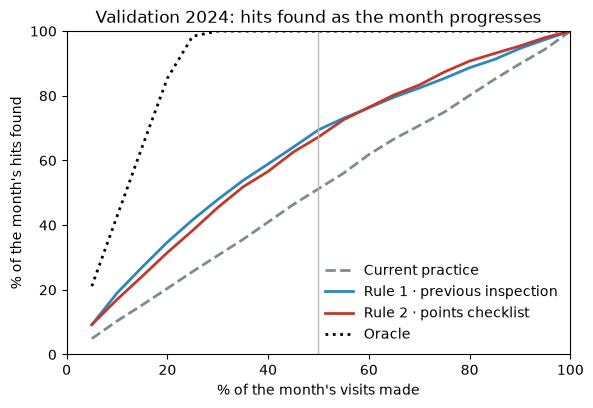

In [12]:
grid = np.linspace(0.05, 1, 20)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
styles = {'Current practice': ('#7f8c8d', '--'), 'Rule 1 · previous inspection': ('#2e86c1', '-'),
          'Rule 2 · points checklist': ('#c0392b', '-'), 'Oracle': ('#000000', ':')}
for name, col in SCORES.items():
    c, ls = styles[name]
    ax.plot(100 * grid, 100 * capture_curve(valid, col, grid), ls, color=c, lw=2, label=name)
ax.axvline(50, color='#bbbbbb', lw=1)
ax.set(xlabel="% of the month's visits made", ylabel="% of the month's hits found", xlim=(0, 100), ylim=(0, 100),
       title='Validation 2024: hits found as the month progresses')
ax.legend(frameon=False, loc='lower right')
plt.show()

**How to read the capture curve**
- **Horizontal axis:** how far down the month's list the inspectors have gone (10% of the month's visits made, 20%, … 100%).
- **Vertical axis:** what share of that month's Priority-violation findings have been made so far.
- **Every line ends at the top-right corner.** By the end of the month every ordering has made all the visits, so all find 100% of the hits. The only difference is **how fast** each line climbs.
- **Current practice** climbs roughly along the diagonal: halfway through the month, about half the hits are found. That's what an order with no risk information looks like.
- **The oracle reaches 100% at about a quarter of the visits, not at 50%.** Only about 23% of visits find a Priority violation, so a perfect order finds them all within roughly the first quarter of the month, then flattens. It is the steepest climb possible.
- **The two rules** sit in between. At the 50% line (the HR@50 cut) they have found about 70% of the month's hits, vs about 50% for current practice and 100% for the oracle. Rule 1 stays slightly above Rule 2 early in the month.

**Why the whole curve, if the headline uses 50%?** To show the conclusion doesn't depend on choosing 50%. At every point along the month, the rules beat current practice and fall short of the oracle, and the order of the methods is the same at 25% or 75%.

**What it does *not* show:** whether the list should be made monthly or more often (e.g. every two weeks). That is a separate question, about the planning period rather than the cut-off.

*HR@50 and the curve are two views of the same thing:* the curve shows the share of **all the month's hits** found by the first half; HR@50 shows the share of **first-half visits** that found one.

### Stability across years (train years, no training involved)

In [13]:
by_year = {}
for year, df in pool.groupby(pool.visit_ts.dt.year):
    b, _ = leaderboard(df)
    by_year[year] = b['extra hits / 100 visits vs current']
stab = pd.DataFrame(by_year)
stab.loc['hit rate'] = pool.groupby(pool.visit_ts.dt.year).hit.mean() * 100
stab.style.format('{:+.1f}').format('{:.1f}%', subset=pd.IndexSlice['hit rate', :])

,2020,2021,2022,2023,2024
Current practice,+0.0,+0.0,+0.0,+0.0,+0.0
Rule 1 · previous inspection,+8.3,+8.3,+10.3,+9.4,+8.5
Rule 2 · points checklist,+7.6,+7.6,+9.7,+8.9,+7.5
Oracle,+20.5,+19.5,+23.4,+18.8,+22.7
hit rate,20.2%,20.5%,22.1%,19.2%,23.2%


**By license type** (validation year). RF has about 60 visits a month, so its numbers are noisy (R11):

In [14]:
seg = {}
for cat, df in valid.groupby('category'):
    b, _ = leaderboard(df)
    seg[cat] = b['HR@50']
seg = pd.DataFrame(seg)
seg.loc['visits per month'] = valid.groupby('category').size() / valid.month.nunique()
seg.style.format('{:.1%}').format('{:.0f}', subset=pd.IndexSlice['visits per month', :])

,FS,FT,RF
Current practice,27.9%,21.7%,16.4%
Rule 1 · previous inspection,36.1%,30.7%,19.6%
Rule 2 · points checklist,35.4%,29.6%,20.2%
Oracle,54.4%,43.6%,29.0%
visits per month,215,192,62


## 6 · Is the metric precise enough? (R11)

How wide are the bootstrap intervals with 12 validation months? This tells us the smallest model improvement we can reliably detect in notebook 03.

In [15]:
lo, hi = bootstrap_diff(pms_valid['Rule 2 · points checklist'], pms_valid['Current practice'])
print(f'Rule 2 vs current, 2024: CI width ≈ {100 * (hi - lo):.1f} points (12 months)')
pms_all = {n: per_month(pool, c) for n, c in SCORES.items()}
lo2, hi2 = bootstrap_diff(pms_all['Rule 2 · points checklist'], pms_all['Current practice'])
print(f'Rule 2 vs current, 2020–24: CI width ≈ {100 * (hi2 - lo2):.1f} points ({len(pms_all["Oracle"])} months)')

Rule 2 vs current, 2024: CI width ≈ 3.7 points (12 months)
Rule 2 vs current, 2020–24: CI width ≈ 1.4 points (60 months)


With one validation year, differences smaller than a few hits per 100 visits are hard to separate from noise. So notebook 03 uses **rolling (backtest) evaluation over 2022, 2023 and 2024**: train on everything before each year, predict that year, then pool the 36 months. This roughly halves the interval width without touching the test period.

## Findings and decisions

**Findings**
1. **Current practice carries no risk signal within the month.** Hits are found at the base rate in the first half, so the opportunity is real.
2. **Headroom:** the oracle roughly doubles the first-half hit rate. That is the ceiling.
3. **"Go back first to the places that were bad last time" (Rule 1) is a strong rule:** +8.5 hits per 100 visits in 2024 (CI +6.5 to +10.5), 37% of the headroom, and +8 to +10 in every year 2020–2024.
4. **Adding checklist items made the rule worse.** Rule 2 trails Rule 1 by 1.0 hit per 100 visits (CI −1.5 to −0.4), a reminder that intuitive extra signals can dilute a strong one.
5. The gains hold for every license type. RF is noisy (about 60 visits a month).
6. One validation year gives wide intervals, so model comparisons should use rolling backtests over 2022–2024.

**Decisions**
- Primary metric: HR@50, reported as extra hits per 100 visits vs current practice and vs **the best rule, Rule 1**, with month-bootstrap CIs. Supporting: share of headroom, capture curve, days earlier.
- **The bar is Rule 1, not Rule 2** as the plan assumed. Models must beat the *best* simple alternative.
- **Phase 1 exit criterion (re-set from the plan's placeholder):** the best tabular model beats Rule 1 on the pooled 2022–24 backtest, with a 95% CI excluding zero, by at least **3 extra hits per 100 visits**. That is about a fifth of the remaining gap between Rule 1 and the oracle (about 14 points), and roughly a third more gain on top of what Rule 1 delivers.